# AWS 939 one-minute data → 5-second simulation

Loads the KMA AWS CSVs in `dataset/` and upsamples them with `modules/simulation/pchip.py`.
`modules/simulation/dataset.py` adapts the raw files to what the upsampler expects:

- decodes the cp949 Korean headers into English column names and merges overlapping exports
- splits every variable into contiguous runs without NaNs (the upsampler requires gap-free 60 s records)
- interpolates wind direction through its unit-vector components (`wind_u`, `wind_v`) instead of as an angle

The output is a deterministic interpolation, not measured 5-second data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from modules.dataset.dataset import DEFAULT_BOUNDS, DEFAULT_MODES, load_aws, simulate

## 1. Load

In [2]:
raw = load_aws("dataset")
print(raw.shape, raw["timestamp"].min(), "→", raw["timestamp"].max())
raw.head()

(841579, 10) 2024-01-01 00:01:00 → 2026-08-09 00:59:00


,station,timestamp,temperature,rain,rain_flag,wind_dir,wind_speed,pressure,sea_pressure,humidity
0,939,2024-01-01 00:01:00,0.7,0.0,0.0,59.9,0.6,1018.8,1025.1,96.0
1,939,2024-01-01 00:02:00,0.8,0.0,0.0,49.8,0.6,1018.8,1025.1,96.0
2,939,2024-01-01 00:03:00,1.0,0.0,0.0,74.3,0.2,1018.8,1025.0,96.0
3,939,2024-01-01 00:04:00,0.9,0.0,0.0,70.6,0.5,1018.8,1025.1,95.3
4,939,2024-01-01 00:05:00,0.8,0.0,0.0,57.0,0.6,1018.8,1025.1,95.1


In [3]:
raw.head(200)

,station,timestamp,temperature,rain,rain_flag,wind_dir,wind_speed,pressure,sea_pressure,humidity
0,939,2024-01-01 00:01:00,0.7,0.0,0.0,59.9,0.6,1018.8,1025.1,96.0
1,939,2024-01-01 00:02:00,0.8,0.0,0.0,49.8,0.6,1018.8,1025.1,96.0
2,939,2024-01-01 00:03:00,1.0,0.0,0.0,74.3,0.2,1018.8,1025.0,96.0
3,939,2024-01-01 00:04:00,0.9,0.0,0.0,70.6,0.5,1018.8,1025.1,95.3
4,939,2024-01-01 00:05:00,0.8,0.0,0.0,57.0,0.6,1018.8,1025.1,95.1
...,...,...,...,...,...,...,...,...,...,...
195,939,2024-01-01 03:16:00,3.8,0.0,0.0,34.8,1.5,1020.3,1026.5,77.7
196,939,2024-01-01 03:17:00,3.9,0.0,0.0,28.5,1.2,1020.3,1026.5,77.9
197,939,2024-01-01 03:18:00,3.8,0.0,0.0,25.7,2.3,1020.3,1026.5,77.8
198,939,2024-01-01 03:19:00,3.9,0.0,0.0,18.5,3.5,1020.3,1026.5,78.0


## 2. Configure

Modes describe how each minute value was measured; change them if the station's reporting differs:

- `point`: instantaneous reading; PCHIP passes through each minute value
- `mean`: minute average; the 5 s values average back to it exactly
- `total`: amount accumulated in the minute (rain); split evenly across the minute

KMA labels each minute by its end, so `interval_label="end"`. A full year at 5 s produces about 6M rows, so start with a short window.

In [4]:
START, END = "2024-01-01", "2026-07-08"   # set both to None for the full dataset
STEP_SECONDS = 20

modes = dict(DEFAULT_MODES)
bounds = dict(DEFAULT_BOUNDS)
modes, bounds

({'temperature': 'point',
  'pressure': 'point',
  'sea_pressure': 'point',
  'humidity': 'point',
  'wind_speed': 'mean',
  'dir_sin': 'mean',
  'dir_cos': 'mean',
  'rain': 'total'},
 {'humidity': (0.0, 100.0),
  'wind_speed': (0.0, None),
  'dir_sin': (-1.0, 1.0),
  'dir_cos': (-1.0, 1.0)})

## 3. Simulate

In [5]:
source = load_aws("dataset", START, END)
sim = simulate(source, modes=modes, bounds=bounds, step_seconds=STEP_SECONDS, interval_label="end")
print(f"{len(source):,} minute rows → {len(sim):,} rows at {STEP_SECONDS}s")
print("source rows skipped (runs too short):", sim.attrs["skipped_source_rows"])
print("NaN before cleaning:", sim.attrs["nan_before_cleaning"])
print(f"rain NaN filled with 0.0; {sim.attrs['dropped_rows']:,} rows with other NaNs dropped")
sim.head(20)

795,439 minute rows → 2,385,742 rows at 20s
source rows skipped (runs too short): {'temperature': 3, 'pressure': 3, 'sea_pressure': 3, 'humidity': 3, 'wind_speed': 3, 'dir_sin': 3, 'dir_cos': 3, 'rain': 3}
NaN before cleaning: {'temperature': 455, 'pressure': 269, 'sea_pressure': 417, 'humidity': 394, 'wind_speed': 203, 'rain': 5471, 'wind_dir': 191, 'wind_u': 203, 'wind_v': 203}
rain NaN filled with 0.0; 652 rows with other NaNs dropped


,temperature,pressure,sea_pressure,humidity,wind_speed,rain,wind_dir,wind_u,wind_v
timestamp,,,,,,,,,
2024-01-01 00:01:00,0.700000,1018.800000,1025.100000,96.000000,0.634568,0.0,48.166641,-0.472809,-0.423235
2024-01-01 00:01:20,0.723457,1018.800000,1025.100000,96.000000,0.634568,0.0,47.561591,-0.468313,-0.428205
2024-01-01 00:01:40,0.758025,1018.800000,1025.100000,96.000000,0.530864,0.0,53.760634,-0.428171,-0.313826
2024-01-01 00:02:00,0.800000,1018.800000,1025.100000,96.000000,0.246914,0.0,70.314724,-0.232483,-0.083174
2024-01-01 00:02:20,0.871605,1018.800000,1025.074074,96.000000,0.143210,0.0,76.511896,-0.139260,-0.033403
2024-01-01 00:02:40,0.958025,1018.800000,1025.025926,96.000000,0.209877,0.0,75.985965,-0.203630,-0.050824
2024-01-01 00:03:00,1.000000,1018.800000,1025.000000,96.000000,0.420576,0.0,72.974134,-0.402143,-0.123146
2024-01-01 00:03:20,0.981481,1018.800000,1025.025926,95.841564,0.520576,0.0,71.161137,-0.492689,-0.168098
2024-01-01 00:03:40,0.940741,1018.800000,1025.074074,95.527572,0.558848,0.0,67.656466,-0.516890,-0.212451


## 4. Consistency checks

Each point value must reappear at its timestamp, each minute mean must be recovered, and each rain total must sum back.

In [6]:
src = source.set_index("timestamp")
minute = dict(rule="1min", label="right", closed="left")  # [t-60s, t) is labeled t
checks = {}
for column, mode in modes.items():
    if column not in src:
        continue
    if mode == "point":
        recovered = sim[column].reindex(src.index)
    elif mode == "mean":
        recovered = sim[column].resample(**minute).mean().reindex(src.index)
    else:
        recovered = sim[column].resample(**minute).sum(min_count=1).reindex(src.index)
    checks[column] = (recovered - src[column]).abs().max()
pd.Series(checks, name="max abs error")

temperature     0.000000
pressure        0.000000
sea_pressure    0.000000
humidity        0.000000
wind_speed      0.447811
rain            0.000000
Name: max abs error, dtype: float64

## 5. Plot one hour

Dots are the source minute values; lines are the 5-second simulation.

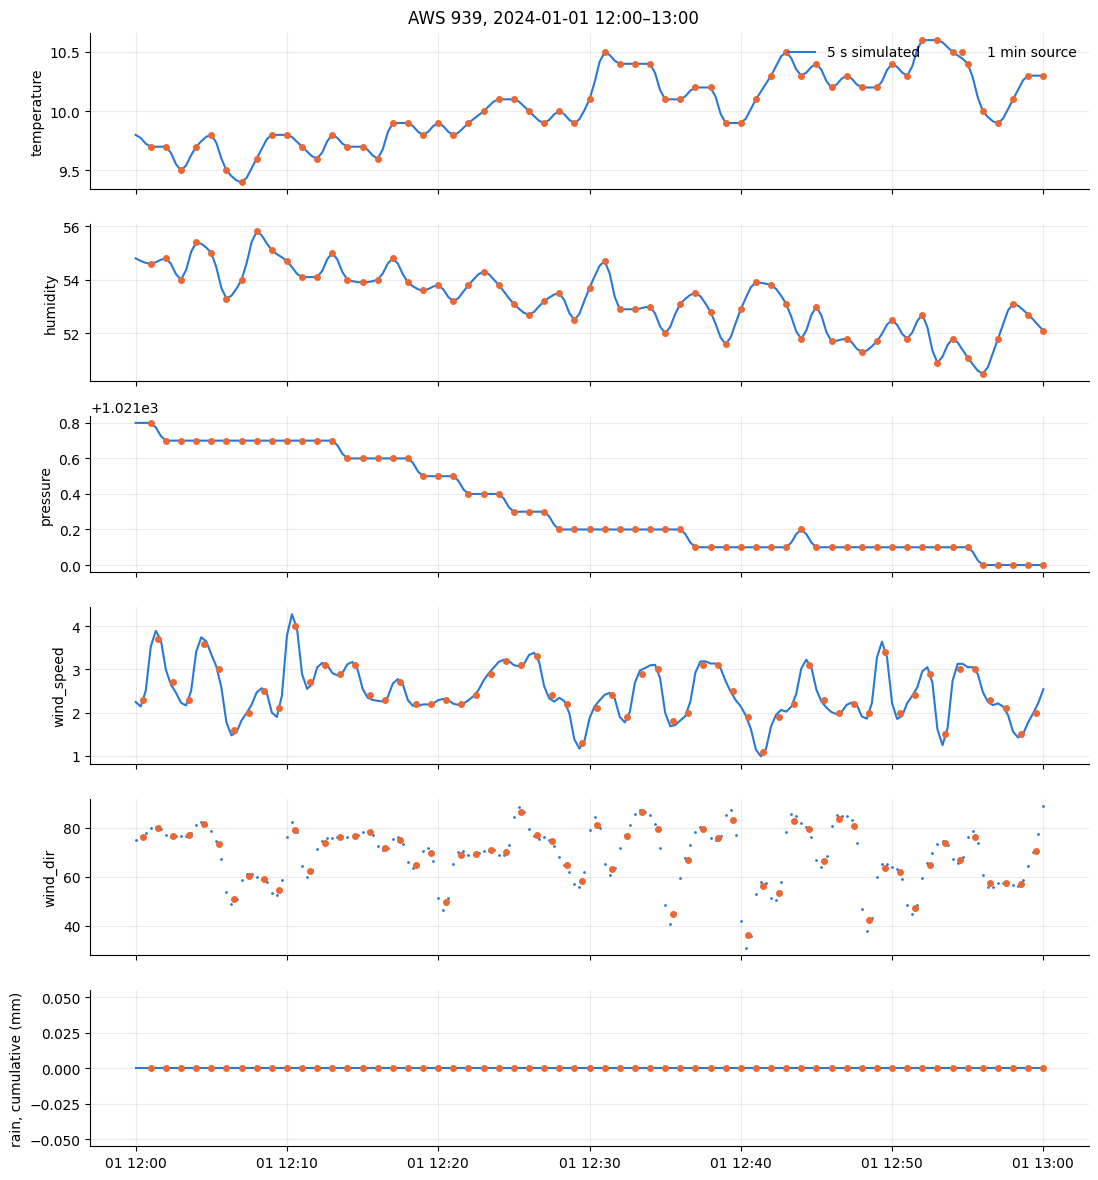

In [7]:
t0 = pd.Timestamp(START or source["timestamp"].iloc[0]) + pd.Timedelta(hours=12)
t1 = t0 + pd.Timedelta(hours=1)
panels = ["temperature", "humidity", "pressure", "wind_speed", "wind_dir", "rain"]
SOURCE, SIM = "#eb6834", "#2a78d6"

fig, axes = plt.subplots(len(panels), 1, figsize=(11, 2.0 * len(panels)), sharex=True)
for ax, column in zip(axes, panels):
    s = sim.loc[t0:t1, column]
    o = src.loc[t0 + pd.Timedelta(minutes=1):t1, column] if column in src else None
    if column == "rain":
        s, o = s.cumsum(), o.cumsum()
    if column == "wind_dir":
        ax.plot(s.index, s, ".", ms=2, color=SIM, label="5 s simulated")
    else:
        ax.plot(s.index, s, lw=1.5, color=SIM, label="5 s simulated")
    if o is not None:
        # mean values describe the preceding minute (plot at its midpoint); a running total is reached at its end
        offset = pd.Timedelta(seconds=-30) if modes.get(column, "mean") == "mean" else pd.Timedelta(0)
        ax.plot(o.index + offset, o, "o", ms=4, color=SOURCE, label="1 min source")
    ax.set_ylabel("rain, cumulative (mm)" if column == "rain" else column)
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].legend(loc="upper right", frameon=False, ncol=2)
fig.suptitle(f"AWS 939, {t0:%Y-%m-%d %H:%M}–{t1:%H:%M}")
fig.tight_layout()

## 6. Save (optional)

In [8]:
SAVE = True
if SAVE:
    from pathlib import Path
    out_dir = Path("simulated_dataset")   # read by labeling.ipynb and training.ipynb
    out_dir.mkdir(exist_ok=True)
    for month, part in sim.groupby(sim.index.to_period("M")):
        part.to_csv(out_dir / f"{month}.csv")
    print("saved", sim.index.to_period("M").nunique(), "monthly files to", out_dir)


saved 19 monthly files to simulated_20s


In [16]:
sim.tail()

,temperature,pressure,sea_pressure,humidity,wind_speed,rain,wind_dir,wind_u,wind_v
timestamp,,,,,,,,,
2026-07-07 23:57:20,25.8,1003.300000,1008.900000,74.022222,2.627160,0.0,205.407822,1.127205,2.373053
2026-07-07 23:57:40,25.8,1003.300000,1008.900000,73.877778,2.623457,0.0,207.313513,1.203797,2.330965
2026-07-07 23:58:00,25.8,1003.300000,1008.900000,73.800000,2.546914,0.0,212.851556,1.381610,2.139608
2026-07-07 23:58:20,25.8,1003.314815,1008.914815,73.803704,2.476543,0.0,217.415320,1.504719,1.967000
2026-07-07 23:58:40,25.8,1003.351852,1008.951852,73.829630,2.476543,0.0,217.415320,1.504719,1.967000
